In [16]:
import numpy as np
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix)

In [2]:
def load_csv_from_user():
    path = input("Enter the path to the CSV file: ").replace('"','')
    
    if not os.path.exists(path):
        print("❌ File not found. Please check the path.")
        return None
    
    try:
        df = pd.read_csv(path)
        df = df.dropna(axis=1, how="all")
        print("✅ File loaded successfully")
        return df
    except Exception as e:
        print("❌ Error reading file:", e)
        return None

In [3]:
df = load_csv_from_user()

Enter the path to the CSV file:  C:\Users\NAGENDRA\.cache\kagglehub\datasets\tanshihjen\aids-clinical-trials\versions\1\AIDS_ClinicalTrial_GroupStudy175.csv


✅ File loaded successfully


In [4]:
columns = df.columns.to_list()
continuous_col = []

In [10]:
columns

['time',
 'trt',
 'age',
 'wtkg',
 'hemo',
 'homo',
 'drugs',
 'karnof',
 'oprior',
 'z30',
 'zprior',
 'preanti',
 'race',
 'gender',
 'str2',
 'strat',
 'symptom',
 'treat',
 'offtrt',
 'cd40',
 'cd420',
 'cd80',
 'cd820',
 'label']

In [5]:
for x in range(0,len(columns)):
    if len(set(df[columns[x]])) > 10:
        continuous_col.append(columns[x])
    else:
        pass

In [6]:
continuous_col

['time', 'age', 'wtkg', 'preanti', 'cd40', 'cd420', 'cd80', 'cd820']

In [7]:
df_1 = pd.get_dummies(df,columns=['trt'],prefix='trt',drop_first=False,dtype=int)

In [8]:
df_1

,time,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,zprior,...,offtrt,cd40,cd420,cd80,cd820,label,trt_0,trt_1,trt_2,trt_3
0,948,48,89.8128,0,0,0,100,0,0,1,...,0,422,477,566,324,0,0,0,1,0
1,1002,61,49.4424,0,0,0,90,0,1,1,...,0,162,218,392,564,1,0,0,0,1
2,961,45,88.4520,0,1,1,90,0,1,1,...,1,326,274,2063,1893,0,0,0,0,1
3,1166,47,85.2768,0,1,0,100,0,1,1,...,0,287,394,1590,966,0,0,0,0,1
4,1090,43,66.6792,0,1,0,100,0,1,1,...,0,504,353,870,782,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2134,1091,21,53.2980,1,0,0,100,0,1,1,...,1,152,109,561,720,0,0,0,0,1
2135,395,17,102.9672,1,0,0,100,0,1,1,...,1,373,218,1759,1030,0,1,0,0,0
2136,1104,53,69.8544,1,1,0,90,0,1,1,...,0,419,364,1391,1041,0,0,0,1,0
2137,465,14,60.0000,1,0,0,100,0,0,1,...,0,166,169,999,1838,1,1,0,0,0


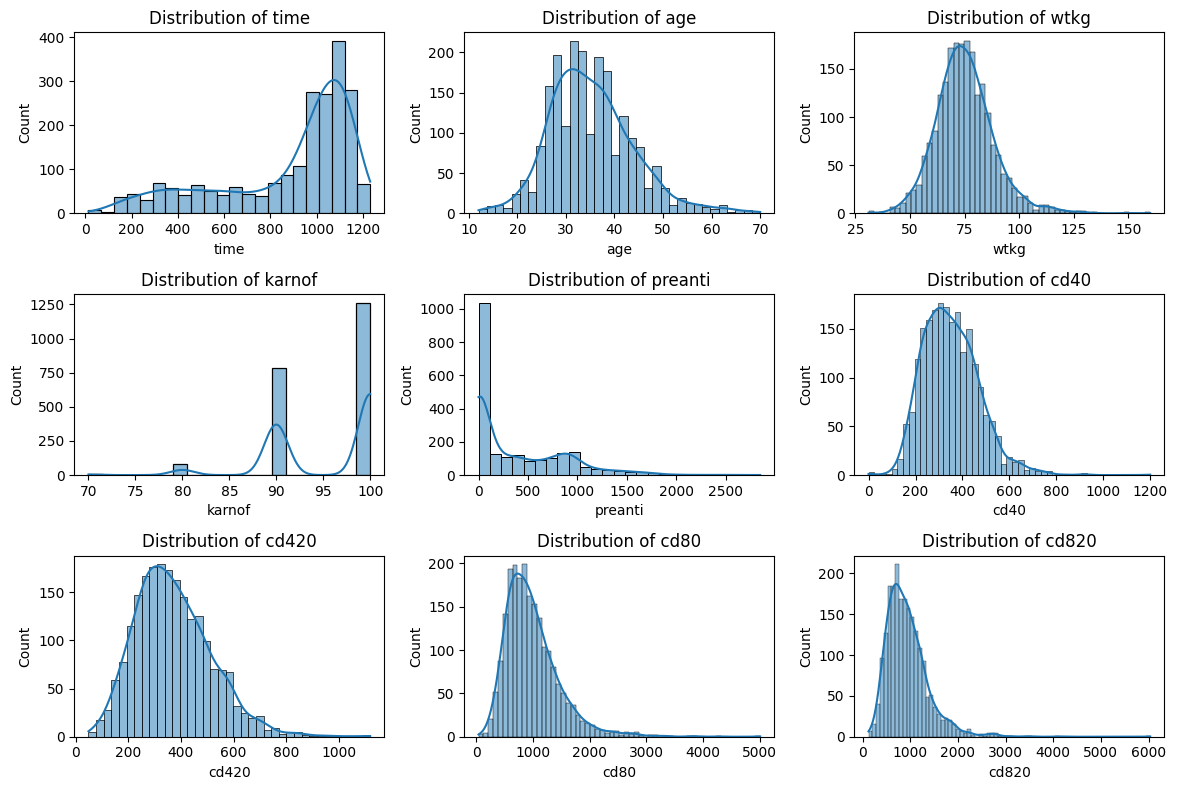

In [78]:
######## star model
# -----------------------------
# 1. Define X and y
# -----------------------------

X = df_1.drop(columns=['label', 'zprior', 'cd420', 'cd820','time'])
y = df_1['label']


# -----------------------------
# 2. Define feature types
# -----------------------------

continuous_features = [
    'age',
    'wtkg',
    'karnof',
    'preanti',
    'cd40',
    'cd80',
]

binary_features = [
    'hemo',
    'homo',
    'drugs',
    'oprior',
    'z30',
    'race',
    'gender',
    'str2',
    'symptom',
    'trt_0',
    'trt_1',
    'trt_2',
    'trt_3'
]


# -----------------------------
# 3. Train-test split
# -----------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# -----------------------------
# 4. Column Transformer
# -----------------------------

preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', StandardScaler(), continuous_features),
        ('binary', 'passthrough', binary_features)
    ]
)


# -----------------------------
# 5. Pipeline
# -----------------------------

model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            class_weight='balanced'
        ))
    ]
)


# -----------------------------
# 6. Train
# -----------------------------

model.fit(X_train, y_train)


# -----------------------------
# 7. Predict
# -----------------------------

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]


# -----------------------------
# 8. Evaluation
# -----------------------------

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1       :", f1)
print("ROC-AUC  :", roc_auc)
print("specificity :", specificity)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.6985981308411215
Precision: 0.4277456647398844
Recall   : 0.7115384615384616
F1       : 0.5342960288808665
ROC-AUC  : 0.7510683760683761
specificity : 0.6944444444444444

Confusion Matrix:
[[225  99]
 [ 30  74]]


In [68]:
################## Random forest
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)


# -----------------------------
# 1. Define X and y
# -----------------------------

X = df_1.drop(
    columns=['label', 'zprior', 'cd420', 'cd820','trt_0','time']
)

y = df_1['label']


# -----------------------------
# 2. Train-test split
# -----------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# -----------------------------
# 3. Random Forest
# -----------------------------

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)


# -----------------------------
# 4. Train
# -----------------------------

rf_model.fit(
    X_train,
    y_train
)


# -----------------------------
# 5. Predictions
# -----------------------------

y_pred = rf_model.predict(X_test)

y_prob = rf_model.predict_proba(
    X_test
)[:, 1]


# -----------------------------
# 6. Evaluation
# -----------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)


# -----------------------------
# 7. Specificity
# -----------------------------

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred
).ravel()

specificity = tn / (tn + fp)


# -----------------------------
# 8. Print results
# -----------------------------

print("Random Forest — Base Model")
print("---------------------------")
print("Accuracy    :", accuracy)
print("Precision   :", precision)
print("Recall      :", recall)
print("Specificity :", specificity)
print("F1          :", f1)
print("ROC-AUC     :", roc_auc)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Random Forest — Base Model
---------------------------
Accuracy    : 0.7616822429906542
Precision   : 0.5555555555555556
Recall      : 0.09615384615384616
Specificity : 0.9753086419753086
F1          : 0.16393442622950818
ROC-AUC     : 0.6594106125356125

Confusion Matrix:
[[316   8]
 [ 94  10]]


In [73]:
########### star model
# ============================================================
# RANDOM FOREST — GRID SEARCH
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)


# -----------------------------
# 1. Define X and y
# -----------------------------

X = df_1.drop(
    columns=['label', 'zprior', 'cd420', 'cd820', 'trt_0','time']
)

y = df_1['label']


# -----------------------------
# 2. Train-test split
# -----------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# -----------------------------
# 3. Base Random Forest
# -----------------------------

rf_model = RandomForestClassifier(
    class_weight='balanced',
    random_state=42
)


# -----------------------------
# 4. Define parameter grid
# -----------------------------

param_grid = {

    'n_estimators': [100, 200, 500, 800],

    'max_depth': [None, 5, 10, 20],

    'min_samples_split': [2, 5, 10],

    'min_samples_leaf': [1, 2, 5]

}


# -----------------------------
# 5. Grid Search
# -----------------------------

grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)


# -----------------------------
# 6. Train Grid Search
# -----------------------------

grid_search.fit(
    X_train,
    y_train
)


# -----------------------------
# 7. Best parameters
# -----------------------------

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV ROC-AUC:")
print(grid_search.best_score_)


# -----------------------------
# 8. Best model
# -----------------------------

best_rf = grid_search.best_estimator_


# -----------------------------
# 9. Predictions
# -----------------------------

y_pred = best_rf.predict(X_test)

y_prob = best_rf.predict_proba(
    X_test
)[:, 1]


# -----------------------------
# 10. Evaluation
# -----------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)


# -----------------------------
# 11. Specificity
# -----------------------------

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred
).ravel()

specificity = tn / (tn + fp)


# -----------------------------
# 12. Print results
# -----------------------------

print("\nRandom Forest — Grid Search")
print("---------------------------")

print("Accuracy    :", accuracy)
print("Precision   :", precision)
print("Recall      :", recall)
print("Specificity :", specificity)
print("F1          :", f1)
print("ROC-AUC     :", roc_auc)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Fitting 5 folds for each of 144 candidates, totalling 720 fits


C:\Users\NAGENDRA\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Parameters:
{'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}

Best CV ROC-AUC:
0.5152610441767068

Random Forest — Grid Search
---------------------------
Accuracy    : 0.7429906542056075
Precision   : 0.4765625
Recall      : 0.5865384615384616
Specificity : 0.7932098765432098
F1          : 0.5258620689655172
ROC-AUC     : 0.7337369420702753

Confusion Matrix:
[[257  67]
 [ 43  61]]
